In [1]:
import pandas as pd
df = pd.read_csv("Inventory_Turnover.csv")

# show total quantity dispensed per month by all vending machines
df['dispense_date'] = pd.to_datetime(df['dispense_date'], dayfirst=True, format='mixed')
df['dispense_month'] = df['dispense_date'].dt.to_period('M')
df = df.groupby('dispense_month').agg(total_qty_dispensed=('qty_dispensed', 'sum'))#.reset_index()
df.info()#  = df[['dispense_month', 'total_qty_dispensed']]

<class 'pandas.core.frame.DataFrame'>
PeriodIndex: 25 entries, 2022-02 to 2024-02
Freq: M
Data columns (total 1 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   total_qty_dispensed  25 non-null     int64
dtypes: int64(1)
memory usage: 400.0 bytes


In [2]:
# Step 1. Test stationarity of the original series (ADF test)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller

# Extract target variable
series = df["total_qty_dispensed"].astype(float)

# Ensure chronological order
series = series.sort_index()

# ADF test
adf_result = adfuller(
    series,
    autolag="AIC"
)

# Display results
adf_output = pd.DataFrame({
    "Metric": [
        "Test Statistic",
        "p-value",
        "Lags Used",
        "Observations Used",
        "Critical Value (1%)",
        "Critical Value (5%)",
        "Critical Value (10%)"
    ],
    "Value": [
        adf_result[0],
        adf_result[1],
        adf_result[2],
        adf_result[3],
        adf_result[4]["1%"],
        adf_result[4]["5%"],
        adf_result[4]["10%"]
    ]
})

print(adf_output.to_string(index=False))

              Metric     Value
      Test Statistic -1.448566
             p-value  0.558784
           Lags Used  1.000000
   Observations Used 23.000000
 Critical Value (1%) -3.752928
 Critical Value (5%) -2.998500
Critical Value (10%) -2.638967


**Interpretation:**
- p-value below 0.05: Reject the null hypothesis; evidence supports stationarity.
- p-value above 0.05: Fail to reject the null hypothesis; insufficient evidence of stationarity.

T-Statistic (-1.448566) and p-value (0.558784) did not provide sufficient evidence of stationarity.

In [3]:
# Step 2. Apply first-order differencing
# First-order differencing
diff_1 = series.diff().dropna()

print("First-order differenced series:")
print(diff_1)

print("\nNumber of observations:", len(diff_1))

First-order differenced series:
dispense_month
2022-03    12336.0
2022-04     -905.0
2022-05      415.0
2022-06      814.0
2022-07     1923.0
2022-08      547.0
2022-09    -2958.0
2022-10     2147.0
2022-11     2315.0
2022-12      362.0
2023-01    -4241.0
2023-02    -7634.0
2023-03     1288.0
2023-04      -26.0
2023-05      724.0
2023-06      -53.0
2023-07      400.0
2023-08      395.0
2023-09     -931.0
2023-10      681.0
2023-11      833.0
2023-12      674.0
2024-01    -1486.0
2024-02    -1681.0
Freq: M, Name: total_qty_dispensed, dtype: float64

Number of observations: 24


In [4]:
# Step 3. Perform ADF test on the differenced series
# ADF test on differenced series
adf_diff = adfuller(
    diff_1,
    autolag="AIC"
)

# Create results table
adf_diff_output = pd.DataFrame({
    "Metric": [
        "Test Statistic",
        "p-value",
        "Lags Used",
        "Observations Used",
        "Critical Value (1%)",
        "Critical Value (5%)",
        "Critical Value (10%)"
    ],
    "Value": [
        adf_diff[0],
        adf_diff[1],
        adf_diff[2],
        adf_diff[3],
        adf_diff[4]["1%"],
        adf_diff[4]["5%"],
        adf_diff[4]["10%"]
    ]
})

print(adf_diff_output.to_string(index=False))

              Metric         Value
      Test Statistic -6.684143e+00
             p-value  4.268111e-09
           Lags Used  0.000000e+00
   Observations Used  2.300000e+01
 Critical Value (1%) -3.752928e+00
 Critical Value (5%) -2.998500e+00
Critical Value (10%) -2.638967e+00


In [5]:
# Compare the original and differenced ADF results:
# Compare both ADF tests
adf_comparison = pd.DataFrame({
    "Series": [
        "Original",
        "First Difference"
    ],
    "ADF Statistic": [
        adf_result[0],
        adf_diff[0]
    ],
    "p-value": [
        adf_result[1],
        adf_diff[1]
    ]
})

print(adf_comparison.round(4))

             Series  ADF Statistic  p-value
0          Original        -1.4486   0.5588
1  First Difference        -6.6841   0.0000


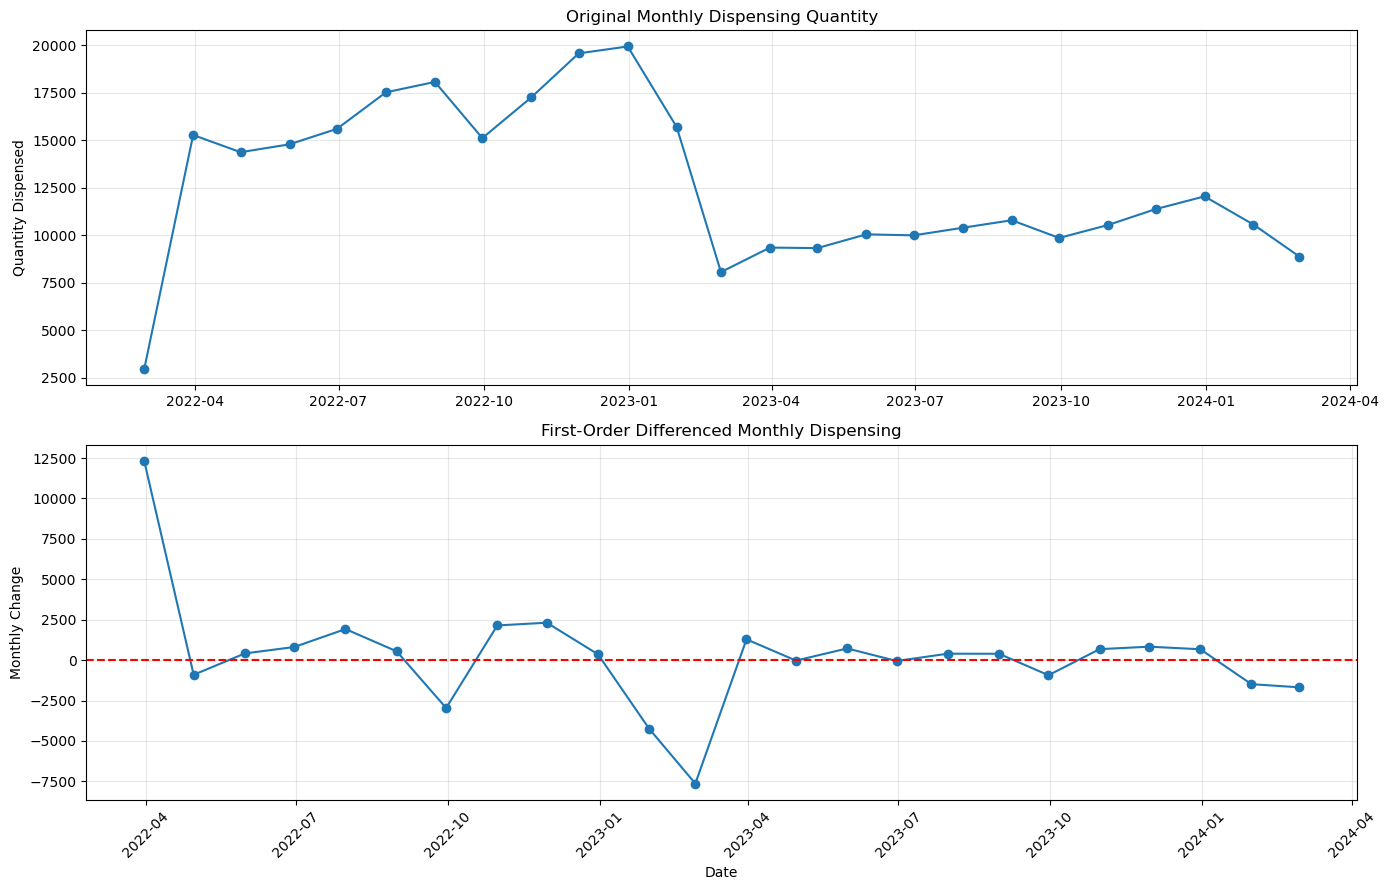

In [6]:
# Step 4. Visualize original and differenced series
fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 9)
)

# Original series
axes[0].plot(
    series.index.to_timestamp("M"),
    series.values,
    marker="o"
)

axes[0].set_title(
    "Original Monthly Dispensing Quantity"
)

axes[0].set_ylabel("Quantity Dispensed")
axes[0].grid(True, alpha=0.3)

# Differenced series
axes[1].plot(
    diff_1.index.to_timestamp("M"),
    diff_1.values,
    marker="o"
)

axes[1].axhline(
    y=0,
    color="red",
    linestyle="--"
)

axes[1].set_title(
    "First-Order Differenced Monthly Dispensing"
)

axes[1].set_ylabel("Monthly Change")
axes[1].set_xlabel("Date")
axes[1].grid(True, alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

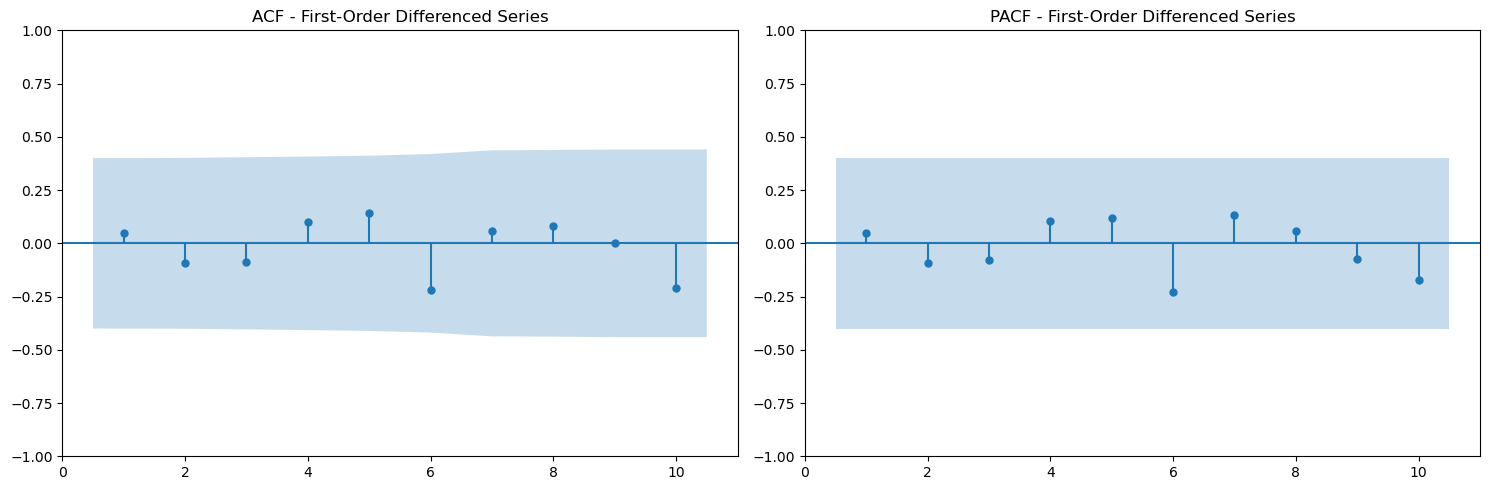

In [7]:
# Step 5. Examine ACF and PACF of the differenced series
from statsmodels.graphics.tsaplots import (
    plot_acf,
    plot_pacf
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5)
)

# ACF
plot_acf(
    diff_1,
    lags=10,
    ax=axes[0],
    zero=False
)

axes[0].set_title(
    "ACF - First-Order Differenced Series"
)

# PACF
plot_pacf(
    diff_1,
    lags=10,
    ax=axes[1],
    zero=False,
    method="ywm"
)

axes[1].set_title(
    "PACF - First-Order Differenced Series"
)

plt.tight_layout()
plt.show()

In [8]:
# Step 6. Compare ARIMA models
# 6A. Fit the candidate models
from statsmodels.tsa.arima.model import ARIMA
import warnings

warnings.filterwarnings("ignore")

# Candidate ARIMA models
orders = [
    (0, 1, 0),
    (1, 1, 0),
    (0, 1, 1),
    (1, 1, 1),
    (2, 1, 0),
    (0, 1, 2),
    (2, 1, 1)
]

arima_results = []

for order in orders:

    try:

        model = ARIMA(
            series,
            order=order,
            enforce_stationarity=False,
            enforce_invertibility=False
        )

        fitted = model.fit()

        arima_results.append({
            "Model": f"ARIMA{order}",
            "AIC": fitted.aic,
            "BIC": fitted.bic,
            "Log_Likelihood": fitted.llf,
            "Converged": fitted.mle_retvals.get(
                "converged", None
            )
        })

    except Exception as e:

        print(f"ARIMA{order} failed: {e}")


arima_comparison = pd.DataFrame(arima_results)

arima_comparison = arima_comparison.sort_values(
    "AIC"
)

print(arima_comparison.round(3).to_string(index=False))

         Model     AIC     BIC  Log_Likelihood  Converged
ARIMA(0, 1, 2) 388.357 391.490        -191.178       True
ARIMA(0, 1, 1) 404.457 406.639        -200.228       True
ARIMA(1, 1, 1) 406.037 409.310        -200.019       True
ARIMA(2, 1, 0) 406.187 409.460        -200.094      False
ARIMA(2, 1, 1) 406.836 411.200        -199.418       True
ARIMA(0, 1, 0) 421.186 422.322        -209.593       True
ARIMA(1, 1, 0) 423.071 425.342        -209.536       True


In [9]:
# 6B. Select the best candidate using AIC
best_arima_name = arima_comparison.iloc[0]["Model"]

print("Best ARIMA candidate based on AIC:")
print(best_arima_name)

Best ARIMA candidate based on AIC:
ARIMA(0, 1, 2)


In [10]:
# 6C. Perform rolling-origin validation
# Rolling-origin validation
initial_train_size = 12

rolling_arima_results = []

for i in range(initial_train_size, len(series)):

    train = series.iloc[:i]
    actual = series.iloc[i]
    forecast_date = series.index[i]

    # Naive forecast
    naive_prediction = train.iloc[-1]

    rolling_arima_results.append({
        "Model": "Naive",
        "Forecast_Date": forecast_date,
        "Actual": actual,
        "Prediction": naive_prediction
    })

    # ARIMA candidates
    for order in orders:

        try:

            model = ARIMA(
                train,
                order=order,
                enforce_stationarity=False,
                enforce_invertibility=False
            )

            fitted = model.fit()

            prediction = fitted.forecast(steps=1).iloc[0]

            rolling_arima_results.append({
                "Model": f"ARIMA{order}",
                "Forecast_Date": forecast_date,
                "Actual": actual,
                "Prediction": prediction
            })

        except Exception:
            continue


rolling_arima_df = pd.DataFrame(
    rolling_arima_results
)

# Calculate errors
rolling_arima_df["Absolute_Error"] = (
    rolling_arima_df["Actual"]
    - rolling_arima_df["Prediction"]
).abs()

rolling_arima_df["Squared_Error"] = (
    rolling_arima_df["Actual"]
    - rolling_arima_df["Prediction"]
) ** 2

rolling_arima_df["APE"] = (
    rolling_arima_df["Absolute_Error"]
    / rolling_arima_df["Actual"].abs()
    * 100
)

# Comparison table
arima_validation = (
    rolling_arima_df
    .groupby("Model")
    .agg(
        MAE=("Absolute_Error", "mean"),
        RMSE=(
            "Squared_Error",
            lambda x: np.sqrt(x.mean())
        ),
        MAPE=("APE", "mean"),
        Forecasts=("Actual", "count")
    )
    .reset_index()
    .sort_values("MAE")
)

print(
    arima_validation.round(2).to_string(index=False)
)

         Model     MAE    RMSE  MAPE  Forecasts
ARIMA(0, 1, 0) 1292.77 2292.01 14.28         13
         Naive 1292.77 2292.01 14.28         13
ARIMA(1, 1, 0) 1378.91 2408.83 15.24         13
ARIMA(0, 1, 1) 1604.63 2686.21 17.72         13
ARIMA(2, 1, 0) 1827.81 2993.92 20.04         13
ARIMA(1, 1, 1) 1844.03 3002.93 20.19         13
ARIMA(2, 1, 1) 1861.05 3013.90 20.47         13
ARIMA(0, 1, 2) 2085.98 3380.28 22.95         13


In [11]:
series.info()

<class 'pandas.core.series.Series'>
PeriodIndex: 25 entries, 2022-02 to 2024-02
Freq: M
Series name: total_qty_dispensed
Non-Null Count  Dtype  
--------------  -----  
25 non-null     float64
dtypes: float64(1)
memory usage: 400.0 bytes


In [12]:
# Compare average monthly dispensing before and after January 2023

before_2023 = series.loc[series.index < "2023-01-01"]
from_2023 = series.loc[series.index >= "2023-01-01"]

comparison = pd.DataFrame({
    "Period": ["Before 2023", "January 2023 onward"],
    "Observations": [
        len(before_2023),
        len(from_2023)
    ],
    "Mean": [
        before_2023.mean(),
        from_2023.mean()
    ],
    "Median": [
        before_2023.median(),
        from_2023.median()
    ],
    "Minimum": [
        before_2023.min(),
        from_2023.min()
    ],
    "Maximum": [
        before_2023.max(),
        from_2023.max()
    ]
})

print(comparison.round(2))

                Period  Observations      Mean   Median  Minimum  Maximum
0          Before 2023            11  15502.18  15607.0   2947.0  19943.0
1  January 2023 onward            14  10500.29  10227.5   8068.0  15702.0
